# Fase 6 — Mejorar el ajuste de la FC y qué le pasa a κ

**Modelo** (Fase 5): $\mathrm{FC}=\mathrm{corr}\big[(\mathrm{diag}\,\theta+L(C))^{-1}\big]$. La matriz de precisión de las señales es un Laplaciano desplazado, así que el modelo es un **modelo gráfico gaussiano con precisión laplaciana**. La EC simétrica es menos la parte fuera de la diagonal de esa precisión, y $C\ge0$ equivale a tener correlaciones parciales no negativas.

Pasos (`src/improve_fc_fit.py`, `src/theta_sensitivity.py`):
1. Techos de ruido: test-retest individual y la FC de grupo usada como plantilla para predecir al individuo.
2. Transformaciones de la SC: $\mathrm{SC}^\alpha$, $\log$, y refuerzo de enlaces interhemisféricos y homotópicos, porque la tractografía subestima las fibras callosas.
3. EC simétrica de grupo, ajustada con los sujetos 0–99 y las sesiones 1–2, y evaluada en los sujetos 100–199.
4. $\kappa$ individual con cada modelo: calidad del ajuste, reproducibilidad y concordancia entre modelos.

techo individual test-retest (mediana r) = 0.894;  plantilla de grupo -> individuo = 0.817
EC simétrica, test en sujetos B: r(GSR) = 0.745

modelo            r(FC) indiv.  kappa med.  ICC4   ICCdía  r(FC media)  ICC sin FC media
SC cruda           0.294        0.0673     0.462  0.607   -0.406       0.404
SC transformada    0.363        0.0000     0.299  0.426   +0.232       0.280
EC simétrica       0.631        0.0026     0.431  0.448   -0.128       0.415


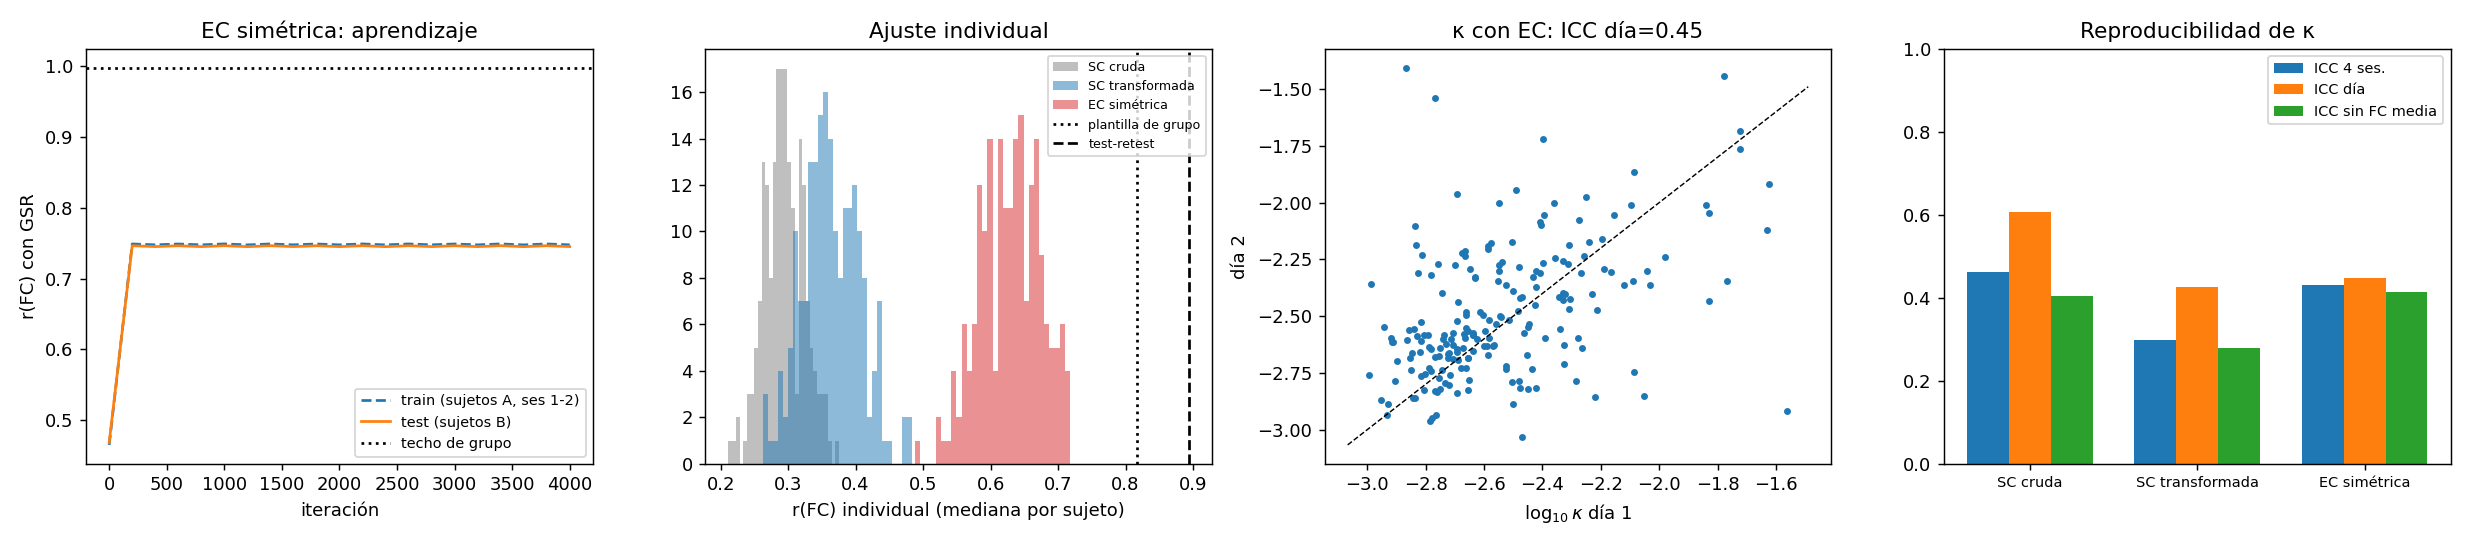

In [1]:
import numpy as np
from pathlib import Path
from IPython.display import Image, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
r = np.load(ROOT/'results'/'fase6_fc_fit.npz')
print(f"techo individual test-retest (mediana r) = {np.median(r['retest']):.3f};  plantilla de grupo -> individuo = {np.median(r['templ']):.3f}")
c = r['curve']; print(f"EC simétrica, test en sujetos B: r(GSR) = {c[-1,3]:.3f}")
print('\nmodelo            r(FC) indiv.  kappa med.  ICC4   ICCdía  r(FC media)  ICC sin FC media')
for n, s in zip(r['names'], r['stats']):
    print(f"{n:17s}  {np.median(r[n+'_RR']):.3f}        {np.median(r[n+'_KA']):.4f}     {s[0]:.3f}  {s[1]:.3f}   {s[2]:+.3f}       {s[3]:.3f}")
display(Image(str(ROOT/'figures'/'fase6_ajuste_fc.png')))

## Resultados del ajuste

| Modelo | r(FC) grupo, sujetos de prueba | r(FC) individual (mediana) |
|---|---|---|
| SC cruda | 0.38 | 0.29 |
| SC$^{0.5}$, interhemisférica ×2, homotópica ×3 | 0.47 | 0.36 |
| **EC simétrica** | **0.80** | **0.63** |
| *Plantilla de grupo (techo para cualquier modelo de grupo)* | *0.997* | *0.78* |
| *Test-retest del mismo sujeto, por sesión* | — | *0.82* |

- La EC simétrica duplica el ajuste y generaliza a sujetos nuevos sin pérdida (0.75 en entrenamiento, 0.75 en prueba), así que no sobreajusta.
- Las transformaciones de la SC dan una mejora modesta: la raíz cuadrada y el refuerzo de las conexiones callosas ayudan.

## Lo que le pasa a κ: el problema de fondo

**1. Cuanto mejor ajusta el modelo, más se va $\theta$ al límite inferior ($\theta\to0$, es decir, $\kappa\to0$).** Con la SC transformada y con la EC, el $\theta$ óptimo con GSR es prácticamente 0.

**2. La razón es exacta.** Con acoplamiento difusivo y $\theta$ homogéneo, el modo más lento de $\theta I+L$ es **exactamente el vector uniforme** ($L\mathbf 1=0$, verificado a $10^{-16}$), y su tasa es $\theta$. **El modo crítico es la señal global.** La GSR elimina justamente ese modo:

In [2]:
import subprocess, sys
print(subprocess.run([sys.executable, '-I', str(ROOT/'src'/'theta_sensitivity.py')], capture_output=True, text=True).stdout)

SC cruda: eigvec lento de L uniforme? |u0 - 1/sqrt(N)| max = 5.8e-16; lambda_2 = 0.1380
   theta=0.3  : |dFC/dlog theta| sin GSR=0.0310   con GSR=0.0163   cociente=0.52
   theta=0.06 : |dFC/dlog theta| sin GSR=0.1046   con GSR=0.0112   cociente=0.11
   theta=0.01 : |dFC/dlog theta| sin GSR=0.2406   con GSR=0.0030   cociente=0.01
EC simétrica: eigvec lento de L uniforme? |u0 - 1/sqrt(N)| max = 1.0e-01; lambda_2 = -0.0000
   theta=0.3  : |dFC/dlog theta| sin GSR=0.0041   con GSR=0.0035   cociente=0.86
   theta=0.06 : |dFC/dlog theta| sin GSR=0.0136   con GSR=0.0101   cociente=0.74
   theta=0.01 : |dFC/dlog theta| sin GSR=0.0432   con GSR=0.0196   cociente=0.45



Cerca de la criticalidad ($\theta=0.01$), la GSR elimina el **99 %** de la sensibilidad de la FC a $\theta$. Esto deja un dilema sin salida:
- **Sin GSR**, $\kappa$ queda determinado por la amplitud de la señal global, que también contienen fuentes no neuronales (respiración, movimiento, nivel de vigilia). Por eso correlaciona $-0.99$ con la FC media.
- **Con GSR**, se elimina justo el modo que lleva la información sobre la distancia a la criticalidad, y $\theta$ queda casi sin identificar.

**3. $\kappa$ depende del modelo.** El orden de los sujetos según $\kappa$ casi no concuerda entre modelos: $r$ de $-0.04$ (cruda frente a transformada), $0.25$ (cruda frente a EC) y $-0.33$ (transformada frente a EC). Su reproducibilidad entre sesiones (ICC de 0.30 a 0.46) refleja *algo* estable de cada sujeto, pero lo que mide cambia según el modelo.

**4. La EC se desconecta.** Al quedar el 85 % de los pesos en cero, 5 regiones terminan aisladas. Cada componente aporta su propio modo de tasa $\theta$, así que $\kappa$ queda degenerado.

## Conclusión
Con modelos lineales difusivos, **la FC a retardo cero no permite medir la distancia a la criticalidad de forma robusta**, ni absoluta (Fase 5) ni relativa (aquí). El modo crítico coincide con la señal global, que está contaminada si se conserva y desaparece si se regresa. Esto **cierra la vía de "FC sola"** y deja dos rutas con fundamento:
1. **Series de tiempo.** La lentitud del modo crítico se ve directamente en la autocorrelación y el espectro de la señal global y de los modos lentos, y se puede separar de los artefactos con regresores fisiológicos (respiración, movimiento) en lugar de con GSR.
2. **Acoplamiento no difusivo** (aditivo, $\sum_k C_{jk}z_k$). Ahí el modo crítico es el eigenvector principal de $C$, que **no** es uniforme, y $G_c=-a/\lambda_{\max}(C)$ (Fase 1). Si los datos favorecen ese modelo, la criticalidad dejaría una firma espacial distinta de la señal global. Esta comparación se puede hacer ya con los 200 sujetos.